# 04 — Add NBA game statistics

Does adding what a player *does on the court* (points, assists, rebounds, threes...) on top of body measurements improve the prediction?

Things to keep in mind:
* This model only works for players who **already have NBA stats**, so it can't be used for draft prospects.
* Stats are converted to **per 36 minutes**, so starters and bench players are comparable.
* Only players with at least 500 career minutes are kept, because stats from a handful of games are mostly noise.

In [1]:
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import truststore
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

truststore.inject_into_ssl()
from nba_api.stats.endpoints import leaguedashplayerstats

sns.set_theme(style="whitegrid")
ORDER = ["PG", "SG", "SF", "PF", "C"]
STATS_RAW = Path("../data/raw/stats_raw.csv")

## 1. Download season totals

One call per season, cached in `data/raw/stats_raw.csv`.

In [2]:
def fetch_season(season):
    df = leaguedashplayerstats.LeagueDashPlayerStats(season=season, per_mode_detailed="Totals",
                                                     timeout=60).get_data_frames()[0]
    time.sleep(1)
    return df.assign(SEASON=season)


if STATS_RAW.exists():
    stats_raw = pd.read_csv(STATS_RAW)
else:
    seasons = [f"{y}-{str(y + 1)[-2:]}" for y in range(2000, 2026)]
    stats_raw = pd.concat([fetch_season(s) for s in seasons], ignore_index=True)
    stats_raw.to_csv(STATS_RAW, index=False)

stats_raw.shape

(12810, 70)

## 2. Career per-36 stats

Add up each player's totals over all seasons, then rescale to 36 minutes.
A few **ratios** describe playing style regardless of how much someone scores:
* `three_rate`: share of shots that are threes
* `ast_to_tov`: assists per turnover
* `oreb_share`: share of rebounds that are offensive

In [3]:
COUNTING = ["PTS", "REB", "OREB", "DREB", "AST", "STL", "BLK", "TOV", "FGA", "FGM", "FG3A", "FG3M", "FTA", "FTM", "PF"]

career = stats_raw.groupby("PLAYER_ID")[["MIN", "GP"] + COUNTING].sum()
career = career[career["MIN"] >= 500]

stats = (career[COUNTING].div(career["MIN"], axis=0) * 36).add_suffix("_36").rename(columns=str.lower)
stats["fg_pct"] = career["FGM"] / career["FGA"]
stats["fg3_pct"] = (career["FG3M"] / career["FG3A"]).fillna(0)
stats["ft_pct"] = career["FTM"] / career["FTA"]
stats["three_rate"] = career["FG3A"] / career["FGA"]
stats["ast_to_tov"] = career["AST"] / career["TOV"].clip(lower=1)
stats["oreb_share"] = career["OREB"] / career["REB"].clip(lower=1)
stats["min_per_game"] = career["MIN"] / career["GP"]
stats = stats.round(3).rename_axis("player_id").reset_index()

players = pd.read_csv("../data/processed/players.csv").merge(stats, on="player_id")
players.to_csv("../data/processed/players_with_stats.csv", index=False)
players["position"].value_counts().reindex(ORDER)

position
PG    191
SG    210
SF    192
PF    211
C      84
Name: count, dtype: int64

## 3. How do stats differ by position?

In [4]:
show = ["pts_36", "ast_36", "reb_36", "blk_36", "fg3a_36", "three_rate", "fg_pct"]
players.groupby("position")[show].mean().reindex(ORDER).round(2)

,pts_36,ast_36,reb_36,blk_36,fg3a_36,three_rate,fg_pct
position,,,,,,,
PG,14.47,5.40,3.97,0.31,4.64,0.37,0.42
SG,14.73,3.17,4.68,0.41,5.07,0.41,0.43
SF,13.67,2.33,5.92,0.61,4.33,0.38,0.44
PF,13.75,1.95,8.85,1.08,2.11,0.18,0.48
C,13.74,1.92,10.48,1.73,1.39,0.11,0.54


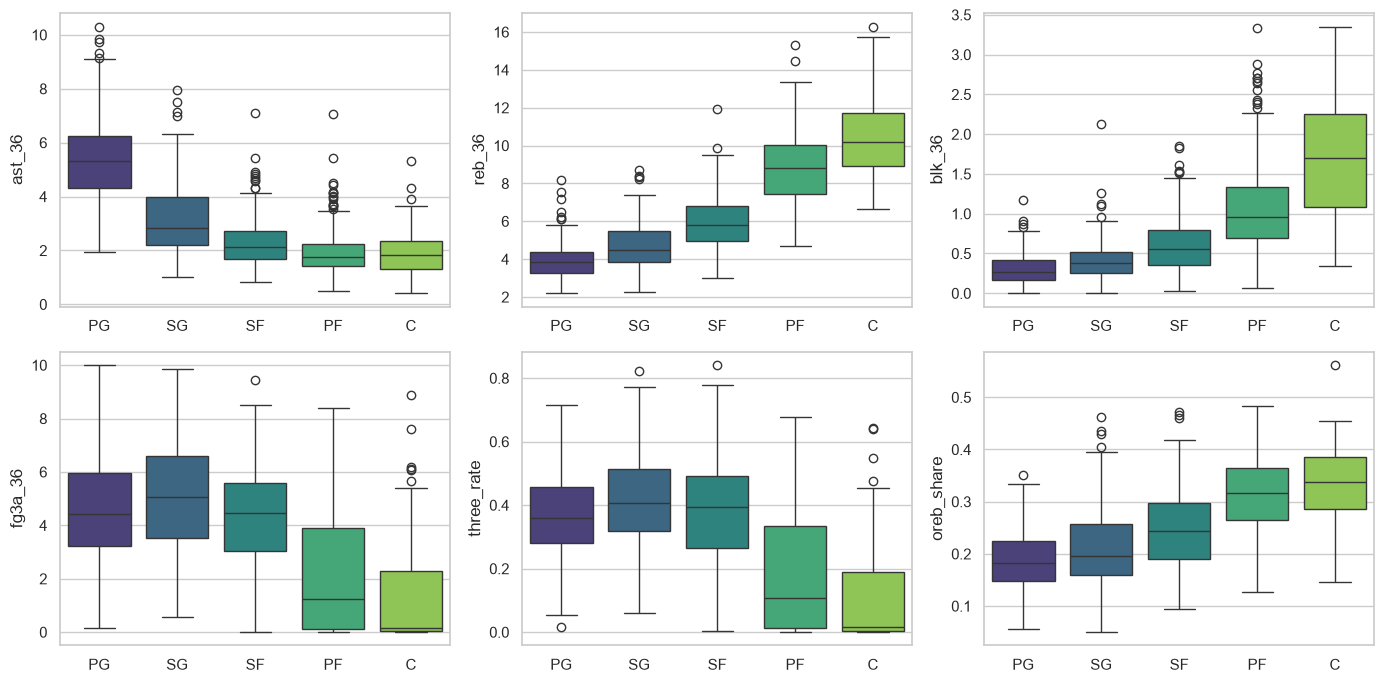

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feature in zip(axes.flat, ["ast_36", "reb_36", "blk_36", "fg3a_36", "three_rate", "oreb_share"]):
    sns.boxplot(data=players, x="position", y=feature, order=ORDER, hue="position", hue_order=ORDER,
                palette="viridis", legend=False, ax=ax)
    ax.set_xlabel("")
fig.tight_layout()

## 4. Compare feature sets on the same players

Same players, same folds, three feature sets:
* **body**: measurements only (like notebook 03)
* **stats**: game statistics only
* **body + stats**: both

In [6]:
BODY = ["height_cm", "weight_kg", "wingspan_cm", "reach_cm", "ape_index_cm", "reach_minus_height_cm", "bmi"]
STATS = [c for c in stats.columns if c != "player_id"]
FEATURE_SETS = {"body": BODY, "stats": STATS, "body + stats": BODY + STATS}

X = players[BODY + STATS]
y = players["position"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

RANK = {p: i for i, p in enumerate(ORDER)}

def adjacent_accuracy(y_true, y_pred):
    true = np.array([RANK[p] for p in y_true])
    pred = np.array([RANK[p] for p in y_pred])
    return np.mean(np.abs(true - pred) <= 1)

def make_pipeline(model):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", model)])

SCORING = {"accuracy": "accuracy", "macro_f1": "f1_macro", "adjacent": make_scorer(adjacent_accuracy)}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
MODELS = {
    "Logistic regression": LogisticRegression(max_iter=5000),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, random_state=42),
}

rows = []
for set_name, cols in FEATURE_SETS.items():
    for name, model in MODELS.items():
        scores = cross_validate(make_pipeline(model), X_train[cols], y_train, cv=CV, scoring=SCORING)
        rows.append({"features": set_name, "model": name, **{m: scores[f"test_{m}"].mean() for m in SCORING}})

results = pd.DataFrame(rows).sort_values("accuracy", ascending=False).reset_index(drop=True)
results.style.format({m: "{:.1%}" for m in SCORING}).background_gradient(subset=["accuracy"], cmap="Greens")

,features,model,accuracy,macro_f1,adjacent
0,body + stats,Logistic regression,75.4%,74.4%,99.0%
1,body + stats,Random forest,74.4%,71.3%,98.9%
2,body + stats,Gradient boosting,70.1%,68.6%,98.7%
3,body,Logistic regression,69.4%,68.8%,99.0%
4,body,Random forest,69.0%,68.5%,98.7%
5,stats,Logistic regression,65.9%,64.4%,98.2%
6,body,Gradient boosting,63.9%,63.4%,98.9%
7,stats,Random forest,63.8%,61.2%,98.0%
8,stats,Gradient boosting,59.9%,57.4%,97.9%


## 5. Best combination on the test set

In [7]:
best = results.iloc[0]
FEATURES = FEATURE_SETS[best["features"]]
final_model = make_pipeline(MODELS[best["model"]]).fit(X_train[FEATURES], y_train)

y_pred = final_model.predict(X_test[FEATURES])
print(classification_report(y_test, y_pred, labels=ORDER))
f"{best['model']} on {best['features']}: adjacent accuracy {adjacent_accuracy(y_test, y_pred):.1%}"

              precision    recall  f1-score   support

          PG       0.77      0.89      0.83        38
          SG       0.70      0.62      0.66        42
          SF       0.74      0.64      0.68        39
          PF       0.78      0.86      0.82        42
           C       0.82      0.82      0.82        17

    accuracy                           0.76       178
   macro avg       0.76      0.77      0.76       178
weighted avg       0.76      0.76      0.75       178



'Logistic regression on body + stats: adjacent accuracy 100.0%'

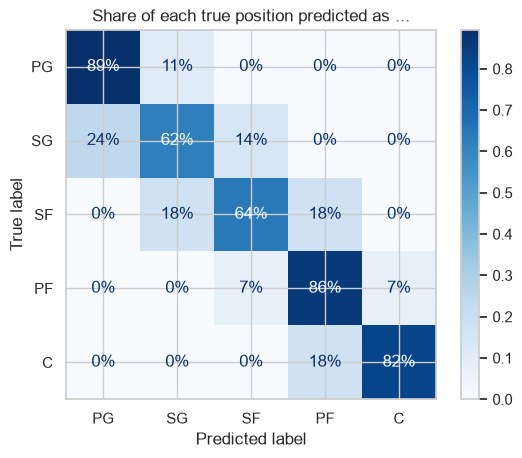

In [8]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=ORDER, cmap="Blues", normalize="true",
                                        values_format=".0%")
plt.title("Share of each true position predicted as ...");

### Which features matter most now?

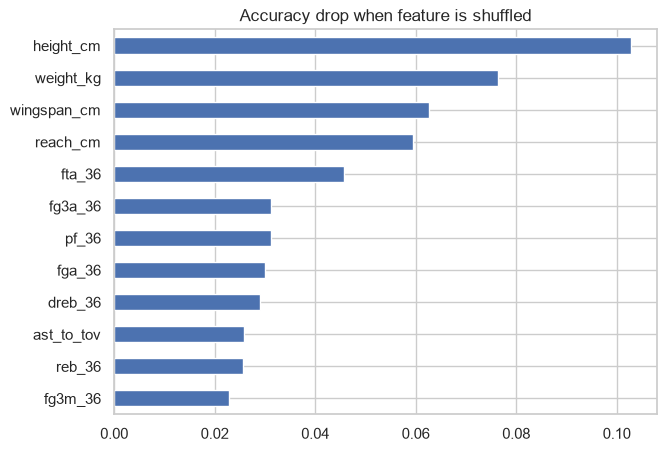

In [9]:
imp = permutation_importance(final_model, X_test[FEATURES], y_test, n_repeats=20, random_state=42)
pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(12).plot.barh(
    figsize=(7, 5), title="Accuracy drop when feature is shuffled");

## 6. Save

Retrain on all players with stats and save next to the body-only model.

In [10]:
final_model.fit(players[FEATURES], players["position"])
joblib.dump({"model": final_model, "features": FEATURES}, "../models/position_model_with_stats.joblib");

## 7. Use it

Look up a player by name. These players were part of the training data, so this is a demo, not a fair test.

In [11]:
import sys

sys.path.insert(0, "..")
from predict import predict_known_player

names = ["Stephen Curry", "Klay Thompson", "Kevin Durant", "Draymond Green", "Rudy Gobert"]
pd.DataFrame({name: predict_known_player(name) for name in names}).reindex(ORDER).style.format("{:.0%}")

,Stephen Curry,Klay Thompson,Kevin Durant,Draymond Green,Rudy Gobert
PG,91%,2%,0%,16%,0%
SG,9%,79%,1%,21%,0%
SF,0%,19%,86%,36%,0%
PF,0%,0%,12%,26%,0%
C,0%,0%,1%,1%,100%
